# NB01: BIDS Data Exploration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB01_BIDS_Exploration.ipynb)


## Learning Objectives
- Understand the Brain Imaging Data Structure (BIDS) standard
- Use PyBIDS to programmatically access study metadata
- Explore subject demographics and acquisition parameters
- Interpret JSON sidecars containing MRI acquisition details
- Examine session-level clinical and cognitive assessment data (CANTAB, psychosocial questionnaires)
- Visualize the study's data organization

## Overview
BIDS is a standardized format for organizing neuroimaging data. This notebook teaches how to programmatically explore BIDS datasets and extract key metadata about acquisitions, subjects, and sessions.

In [31]:
# Setup paths and imports
import os
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np

# Environment setup (same as NB00)
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             '/content/glioma-brain-digital-twin'],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r /content/glioma-brain-digital-twin/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python /content/glioma-brain-digital-twin/data/download_data.py
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DATA_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop'
sys.path.insert(0, str(REPO_ROOT))

print(f'Repository root: {REPO_ROOT}')
print(f'Data root:       {DATA_ROOT}')
print(f'Data exists:     {DATA_ROOT.exists()}')

Repository root: <REPO_ROOT>
Data root:       <REPO_ROOT>/data/BIDS_preop_postop
Data exists:     True


### 1. BIDS Standard Overview

In [32]:
# Explain the BIDS directory structure
bids_explanation = 'BIDS DIRECTORY STRUCTURE\n' + '=' * 24 + '''\n\nA typical BIDS dataset has this hierarchy:\n\ndataset/\n|-- sub-<label>/\n|   |-- ses-<label>/  (optional, for longitudinal studies)\n|   |   |-- anat/     (anatomical images: T1w, T2w, etc.)\n|   |   |-- dwi/      (diffusion weighted images)\n|   |   |-- func/     (functional images: task fMRI)\n|   |   L-- fmap/     (field maps for distortion correction)\n|-- sub-<label>/\n|-- participants.tsv  (subject demographics)\n|-- CHANGES           (dataset version history)\n|-- README            (dataset description)\nL-- dataset_description.json\n\nKEY ADVANTAGES OF BIDS:\n1. Standardized naming and organization\n2. Machine-readable acquisition parameters (JSON sidecars)\n3. Facilitates data sharing and reproducibility\n4. Tools can automatically understand data structure\n5. Supports longitudinal and multi-session studies\n'''

print(bids_explanation)

BIDS DIRECTORY STRUCTURE

A typical BIDS dataset has this hierarchy:

dataset/
|-- sub-<label>/
|   |-- ses-<label>/  (optional, for longitudinal studies)
|   |   |-- anat/     (anatomical images: T1w, T2w, etc.)
|   |   |-- dwi/      (diffusion weighted images)
|   |   |-- func/     (functional images: task fMRI)
|   |   L-- fmap/     (field maps for distortion correction)
|-- sub-<label>/
|-- participants.tsv  (subject demographics)
|-- CHANGES           (dataset version history)
|-- README            (dataset description)
L-- dataset_description.json

KEY ADVANTAGES OF BIDS:
1. Standardized naming and organization
2. Machine-readable acquisition parameters (JSON sidecars)
3. Facilitates data sharing and reproducibility
4. Tools can automatically understand data structure
5. Supports longitudinal and multi-session studies



### 2. Load BIDS Layout and Summary Statistics

In [33]:
# Initialize BIDSLayout and get summary
try:
    from bids import BIDSLayout
    
    if DATA_ROOT.exists():
        print(f'Initializing BIDSLayout for {DATA_ROOT}')
        # validate=False speeds up initialization for large datasets
        layout = BIDSLayout(str(DATA_ROOT), validate=False)
        
        print('\n' + '=' * 60)
        print('BIDS DATASET SUMMARY')
        print('=' * 60)
        
        subjects = layout.get_subjects()
        print(f'\nSubjects ({len(subjects)}): {", ".join(sorted(subjects))}')
        
        # Get sessions
        sessions = layout.get_sessions()
        if sessions:
            print(f'Sessions ({len(sessions)}): {", ".join(sorted(sessions))}')
        else:
            print('Sessions: None (single-session study)')
        
        # Get modalities
        modalities = layout.get_modalities()
        print(f'Modalities ({len(modalities)}): {", ".join(sorted(modalities))}')
        
        # Get extensions
        extensions = layout.get_extensions()
        print(f'File types: {", ".join(sorted(extensions))}')
        
    else:
        print(f'Data directory not found at {DATA_ROOT}')
        layout = None
        
except ImportError:
    print('PyBIDS not installed. Install with: pip install pybids')
    layout = None

Initializing BIDSLayout for <REPO_ROOT>/data/BIDS_preop_postop

BIDS DATASET SUMMARY

Subjects (1): PAT16
Sessions (2): postop, preop
Modalities (0): 
File types: .bval, .bvec, .json, .nii.gz, .tsv


### 3. Explore File Types and Counts

In [34]:
# Detailed file inventory
if layout:
    print('\n' + '=' * 60)
    print('FILE INVENTORY BY TYPE')
    print('=' * 60)
    
    # Get all files grouped by type
    file_counts = {}
    
    # Anatomical files
    t1w_files = layout.get(suffix='T1w', extension='.nii.gz')
    file_counts['T1w'] = len(t1w_files)
    
    t2w_files = layout.get(suffix='T2w', extension='.nii.gz')
    file_counts['T2w'] = len(t2w_files)
    
    # Diffusion files
    dwi_files = layout.get(suffix='dwi', extension='.nii.gz')
    file_counts['DWI'] = len(dwi_files)
    
    # Functional (BOLD) files
    bold_files = layout.get(suffix='bold', extension='.nii.gz')
    file_counts['BOLD (fMRI)'] = len(bold_files)
    
    # Derivatives: tumor masks
    mask_files = []
    derivs_path = DATA_ROOT / 'derivatives' / 'tumor_masks'
    if derivs_path.exists():
        mask_files = list(derivs_path.rglob('*tumor*'))
    file_counts['Tumor Masks'] = len(mask_files)
    
    # Derivatives: rsHRF maps
    rshrf_path = DATA_ROOT / 'derivatives' / 'rsHRF'
    rshrf_files = list(rshrf_path.rglob('*.nii.gz')) if rshrf_path.exists() else []
    file_counts['rsHRF maps'] = len(rshrf_files)
    
    # Derivatives: TVB connectivity
    tvb_path = DATA_ROOT / 'derivatives' / 'TVB'
    tvb_files = list(tvb_path.rglob('*')) if tvb_path.exists() else []
    tvb_files = [f for f in tvb_files if f.is_file() and not f.name.startswith('.')]
    file_counts['TVB derivatives'] = len(tvb_files)
    
    for ftype, count in file_counts.items():
        print(f'  {ftype:15} {count:3d} files')
    
    print(f'\nTotal NIfTI files: {sum(file_counts.values())}')


FILE INVENTORY BY TYPE
  T1w               2 files
  T2w               0 files
  DWI               4 files
  BOLD (fMRI)       2 files
  Tumor Masks       4 files
  rsHRF maps        6 files
  TVB derivatives   5 files

Total NIfTI files: 23


### 4. Participants Demographics

In [35]:
# Load and display participants table
if DATA_ROOT.exists():
    participants_file = DATA_ROOT / 'participants.tsv'

    if participants_file.exists():
        print('=' * 60)
        print('PARTICIPANTS TABLE')
        print('=' * 60)

        df_participants = pd.read_csv(participants_file, sep='\t')
        print(f'\nShape: {df_participants.shape}')
        print(f'Columns: {list(df_participants.columns)}\n')

        core_cols = ['participant_id', 'sex', 'age', 'tumor_type_and_grade',
                     'tumor_size_cm3', 'tumor_location', 'handedness']
        extra_cols = [c for c in df_participants.columns if c not in core_cols]

        print('--- Core demographics ---')
        print(df_participants[core_cols].to_string(index=False))

        if extra_cols:
            print('\n--- Additional phenotypic fields ---')
            print(df_participants[['participant_id'] + extra_cols].to_string(index=False))

        participants_json = DATA_ROOT / 'participants.json'
        if participants_json.exists():
            with open(participants_json) as f:
                meta = json.load(f)
            print('\n--- Column descriptions (from participants.json) ---')
            for col, info in meta.items():
                desc = info.get('Description', '')
                units = info.get('Units', '')
                suffix = f' [{units}]' if units else ''
                print(f'  {col:25s} {desc}{suffix}')
    else:
        print('participants.tsv not found')
        print('Each subject should have a row in participants.tsv')
        print('This file contains demographic information.')

PARTICIPANTS TABLE

Shape: (1, 10)
Columns: ['participant_id', 'sex', 'age', 'tumor_type_and_grade', 'tumor_size_cm3', 'tumor_location', 'handedness', 'height_cm', 'weight_kg', 'fmri_tr_ms']

--- Core demographics ---
participant_id sex  age          tumor_type_and_grade  tumor_size_cm3  tumor_location  handedness
     sub-PAT16   M   39 Anaplastic astrocytoma II-III           50.24 Fronto-temporal           1

--- Additional phenotypic fields ---
participant_id  height_cm  weight_kg  fmri_tr_ms
     sub-PAT16        181         90        2400

--- Column descriptions (from participants.json) ---
  participant_id            Unique participant identifier
  sex                       Sex of the participant
  age                       Age at the time of pre-operative scanning [years]
  tumor_type_and_grade      Tumor type and WHO grade
  tumor_size_cm3            Pre-operative tumor volume [cm^3]
  tumor_location            Anatomical location of the tumor
  handedness                Edinb

### 4b. Session-Level Clinical & Cognitive Data

BIDS allows per-subject session-level phenotypic files (`<subject>_sessions.tsv` + sidecar `.json`).
For sub-PAT16, this includes:

| Category | Instruments |
|----------|-------------|
| **Psychosocial** | STAI (anxiety), PSWQ (worry), ERQ (emotion regulation), UCLA Loneliness |
| **Demographics** | Marital status, education, employment |
| **Lifestyle** | Sport, smoking, caffeine, alcohol (absolute pre-op, change at post-op) |
| **CANTAB Cognitive Battery** | MOT (motor screening), RTI (reaction time), RVP (sustained attention), SOC (planning), SSP (spatial span) |

These data are sourced from the OpenNeuro releases
([ds001226](https://openneuro.org/datasets/ds001226) pre-op,
[ds002080](https://openneuro.org/datasets/ds002080) post-op)
and allow us to relate brain structure/function changes to cognitive outcomes.

SESSION-LEVEL DATA  (sub-PAT16)
Sessions: ['ses-preop', 'ses-postop']
Columns : 48

--- Psychosocial questionnaires ---
session_id  stai  pswq  loneliness  erq_reappraisal  erq_suppression  erq_processing  erq_expression
 ses-preop    36    54          40               24               17               8              10
ses-postop    30    61          50               14               19               4               8

--- CANTAB cognitive battery (selected metrics) ---
  MOT latency (ms)              pre=     817.8  post=     844.5  Δ=+26.7 (+3.3%)
  RTI simple RT (ms)            pre=    403.78  post=345.5555555556  Δ=-58.2 (-14.4%)
  RTI five-choice RT            pre=     361.5  post=     327.0  Δ=-34.5 (-9.5%)
  RVP A' (signal det.)          pre=      0.95  post=0.9523552615  Δ=+0.0 (+0.2%)
  SOC min-move solved           pre=         8  post=         8  Δ=+0.0 (+0.0%)
  SSP span length               pre=         6  post=         7  Δ=+1.0 (+16.7%)


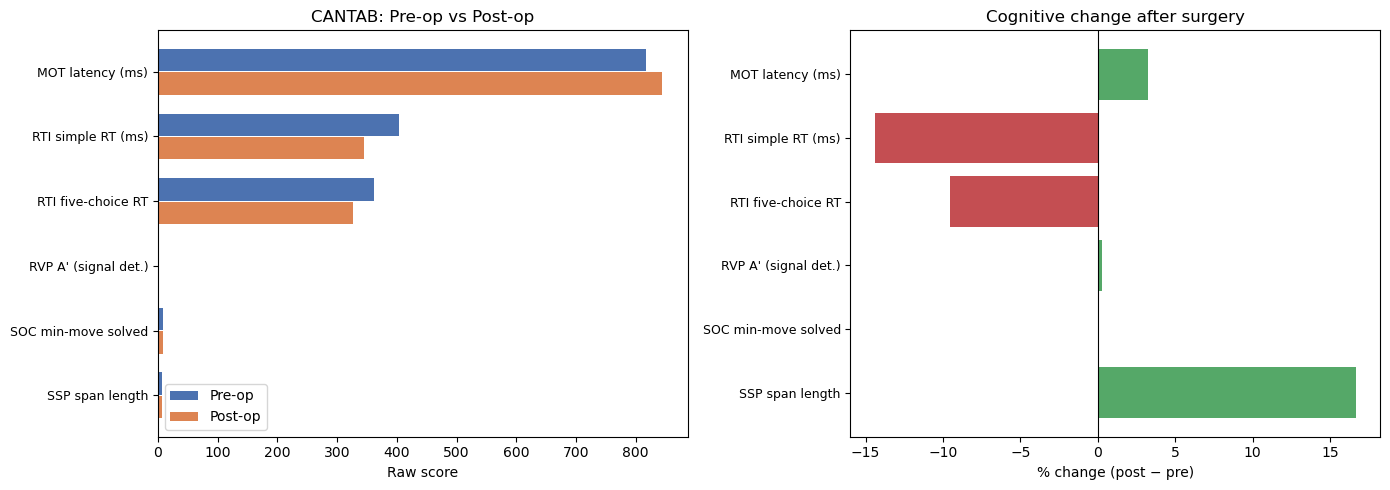

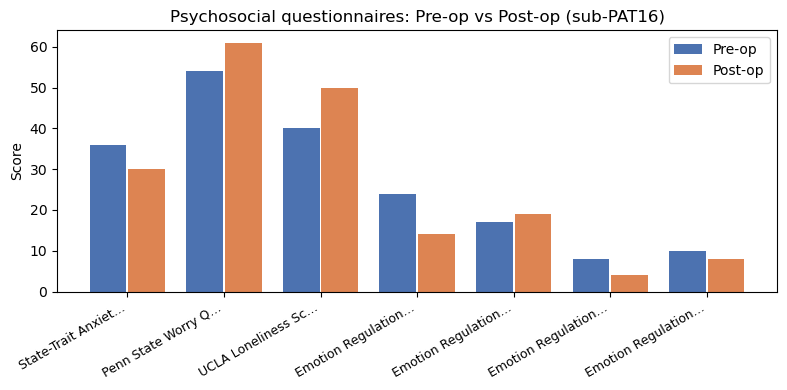

In [36]:
import matplotlib.pyplot as plt

sessions_tsv = DATA_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.tsv'
sessions_json = DATA_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.json'

if sessions_tsv.exists():
    df_ses = pd.read_csv(sessions_tsv, sep='\t')
    print('=' * 60)
    print('SESSION-LEVEL DATA  (sub-PAT16)')
    print('=' * 60)
    print(f'Sessions: {list(df_ses["session_id"])}')
    print(f'Columns : {len(df_ses.columns)}\n')

    meta_ses = {}
    if sessions_json.exists():
        with open(sessions_json) as f:
            meta_ses = json.load(f)

    # --- Psychosocial questionnaires ---
    psych_cols = ['stai', 'pswq', 'loneliness',
                  'erq_reappraisal', 'erq_suppression',
                  'erq_processing', 'erq_expression']
    avail = [c for c in psych_cols if c in df_ses.columns]
    if avail:
        print('--- Psychosocial questionnaires ---')
        print(df_ses[['session_id'] + avail].to_string(index=False))
        print()

    # --- CANTAB key metrics ---
    cantab_summary = {
        'MOT latency (ms)':      'mot_latency_mean',
        'RTI simple RT (ms)':    'rti_simple_rt_mean',
        'RTI five-choice RT':    'rti_five_rt',
        'RVP A\' (signal det.)': 'rvp_a',
        'SOC min-move solved':   'soc_prob_min_moves',
        'SSP span length':       'ssp_span_length',
    }
    cantab_avail = {k: v for k, v in cantab_summary.items() if v in df_ses.columns}

    if cantab_avail:
        print('--- CANTAB cognitive battery (selected metrics) ---')
        for label, col in cantab_avail.items():
            vals = df_ses.set_index('session_id')[col]
            pre = vals.get('ses-preop', 'n/a')
            post = vals.get('ses-postop', 'n/a')
            try:
                delta = float(post) - float(pre)
                pct = 100 * delta / float(pre) if float(pre) != 0 else float('nan')
                print(f'  {label:28s}  pre={pre:>10}  post={post:>10}  Δ={delta:+.1f} ({pct:+.1f}%)')
            except (ValueError, TypeError):
                print(f'  {label:28s}  pre={pre:>10}  post={post:>10}')

    # --- Visualization: pre vs post comparison ---
    norm_metrics = {}
    for label, col in cantab_avail.items():
        vals = df_ses.set_index('session_id')[col]
        try:
            pre_v = float(vals['ses-preop'])
            post_v = float(vals['ses-postop'])
            norm_metrics[label] = (pre_v, post_v)
        except (ValueError, TypeError):
            pass

    if norm_metrics:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        labels = list(norm_metrics.keys())
        pre_vals = [norm_metrics[l][0] for l in labels]
        post_vals = [norm_metrics[l][1] for l in labels]
        x = np.arange(len(labels))

        ax = axes[0]
        ax.barh(x - 0.18, pre_vals, 0.35, label='Pre-op', color='#4C72B0')
        ax.barh(x + 0.18, post_vals, 0.35, label='Post-op', color='#DD8452')
        ax.set_yticks(x)
        ax.set_yticklabels(labels, fontsize=9)
        ax.set_xlabel('Raw score')
        ax.set_title('CANTAB: Pre-op vs Post-op')
        ax.legend()
        ax.invert_yaxis()

        pct_change = []
        pct_labels = []
        for l in labels:
            pre_v, post_v = norm_metrics[l]
            if pre_v != 0:
                pct_change.append(100 * (post_v - pre_v) / pre_v)
                pct_labels.append(l)
        ax2 = axes[1]
        colors = ['#55A868' if v >= 0 else '#C44E52' for v in pct_change]
        ax2.barh(range(len(pct_labels)), pct_change, color=colors)
        ax2.set_yticks(range(len(pct_labels)))
        ax2.set_yticklabels(pct_labels, fontsize=9)
        ax2.axvline(0, color='k', linewidth=0.8)
        ax2.set_xlabel('% change (post − pre)')
        ax2.set_title('Cognitive change after surgery')
        ax2.invert_yaxis()

        plt.tight_layout()
        plt.show()

    # --- Psychosocial bar chart ---
    psych_numeric = {}
    for col in avail:
        vals = df_ses.set_index('session_id')[col]
        try:
            psych_numeric[col] = (float(vals['ses-preop']), float(vals['ses-postop']))
        except (ValueError, TypeError):
            pass

    if psych_numeric:
        fig, ax = plt.subplots(figsize=(8, 4))
        labels_p = list(psych_numeric.keys())
        pre_p = [psych_numeric[l][0] for l in labels_p]
        post_p = [psych_numeric[l][1] for l in labels_p]
        x_p = np.arange(len(labels_p))
        ax.bar(x_p - 0.2, pre_p, 0.38, label='Pre-op', color='#4C72B0')
        ax.bar(x_p + 0.2, post_p, 0.38, label='Post-op', color='#DD8452')
        ax.set_xticks(x_p)
        desc_labels = []
        for c in labels_p:
            d = meta_ses.get(c, {}).get('Description', c)
            short = d.split('—')[0].split('total')[0].strip()
            if len(short) > 20:
                short = short[:18] + '…'
            desc_labels.append(short)
        ax.set_xticklabels(desc_labels, rotation=30, ha='right', fontsize=9)
        ax.set_ylabel('Score')
        ax.set_title('Psychosocial questionnaires: Pre-op vs Post-op (sub-PAT16)')
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    print('No sessions.tsv found for sub-PAT16.')

### Interpretation of Session-Level Results (sub-PAT16)

#### CANTAB Cognitive Battery

The CANTAB (Cambridge Neuropsychological Test Automated Battery) provides
standardised, computerised assessments of specific cognitive domains. For
sub-PAT16, several noteworthy pre- to post-operative changes emerge:

| Metric | Pre-op | Post-op | Change | Interpretation |
|--------|--------|---------|--------|----------------|
| **RTI simple RT** | 404 ms | 346 ms | −14.4% | **Improved** — faster simple reaction time post-surgery, suggesting reduced mass effect on motor/attention circuits |
| **RTI five-choice RT** | 362 ms | 327 ms | −9.5% | **Improved** — faster choice reaction time, consistent with reduced cognitive load from tumor |
| **SSP span length** | 6 | 7 | +16.7% | **Improved** — larger spatial working memory span, implicating parietal network recovery |
| **MOT latency** | 818 ms | 845 ms | +3.3% | **Marginal decline** — slightly slower motor screening, possibly reflecting post-surgical fatigue or subtle motor pathway disruption |
| **RVP A′** | 0.95 | 0.95 | +0.2% | **Stable** — sustained attention (signal detection) preserved |
| **SOC min-move** | 8 | 8 | 0% | **Stable** — spatial planning ability (frontal executive function) preserved |

**Overall cognitive pattern:** The patient shows net cognitive *improvement*
post-operatively, particularly in processing speed (RTI) and spatial working
memory (SSP). This is consistent with the hypothesis that tumor resection
relieved mass effect on neighbouring neural circuits. The stability of RVP
and SOC suggests that sustained attention and executive planning networks
were not adversely affected by surgery.

#### Psychosocial Questionnaires

| Questionnaire | Pre-op | Post-op | Direction | Interpretation |
|---------------|--------|---------|-----------|----------------|
| **STAI** (anxiety) | 36 | 30 | ↓ Decreased | Reduced anxiety post-surgery — possibly reflecting relief from diagnostic uncertainty |
| **PSWQ** (worry) | 54 | 61 | ↑ Increased | Elevated worry — may reflect concerns about recurrence, prognosis, or lifestyle changes |
| **UCLA Loneliness** | 40 | 50 | ↑ Increased | Greater perceived loneliness — consistent with post-operative social withdrawal or sick leave |
| **ERQ reappraisal** | 24 | 14 | ↓ Decreased | Reduced cognitive reappraisal — potentially diminished capacity or motivation for positive reframing |
| **ERQ suppression** | 17 | 19 | ↑ Slight increase | Marginally more expressive suppression |

**Overall psychosocial pattern:** Despite cognitive improvement, the patient
reports increased worry and loneliness post-operatively. This dissociation
between cognitive recovery and psychosocial burden is well-documented in
neuro-oncology (e.g., Ownsworth et al., 2015) and underscores the importance
of including both cognitive *and* psychosocial measures in a clinical digital
twin framework.

#### Relevance to the Digital Twin

These data constitute **Layer 5** of the five-layer digital twin architecture
(see NB08). The mechanical model (Layers 1–4) predicts which white matter
tracts and cortical regions are structurally disrupted by the tumor and its
resection. Layer 5 asks whether those predictions translate to *measurable*
functional change. For sub-PAT16:

- The **RTI improvement** is consistent with preserved/recovered motor and
  attentional pathways (precentral, superior frontal, insula)
- The **SSP improvement** suggests parietal network recovery (superior/inferior
  parietal, precuneus)
- The **psychosocial decline** highlights that structural recovery alone does
  not guarantee patient well-being — a complete digital twin must account for
  psychological dimensions beyond the mechanical model

### 5. Acquisition Parameters from JSON Sidecars

In [20]:
# Load and display acquisition parameters from JSON sidecars
if layout and t1w_files:
    print('\n' + '=' * 60)
    print('ACQUISITION PARAMETERS (T1w Example)')
    print('=' * 60)
    
    # Get first T1w file
    first_t1 = t1w_files[0]
    json_file = first_t1.path.replace('.nii.gz', '.json')
    
    if os.path.exists(json_file):
        with open(json_file, 'r') as f:
            params = json.load(f)
        
        print(f'\nFile: {os.path.basename(json_file)}')
        print('\nKey acquisition parameters:')
        
        key_params = [
            'RepetitionTime', 'EchoTime', 'FlipAngle', 
            'Manufacturer', 'MagneticFieldStrength',
            'EchoTrainLength', 'InversionTime'
        ]
        
        for param in key_params:
            if param in params:
                value = params[param]
                print(f'  {param:25} {value}')
        
        print(f'\nAll parameters ({len(params)} total):')
        for key, value in sorted(params.items()):
            if key not in key_params:
                print(f'  {key:25} {value}')
    else:
        print(f'JSON sidecar not found at {json_file}')
        print('JSON files accompany NIfTI files and contain acquisition details.')


ACQUISITION PARAMETERS (T1w Example)

File: sub-PAT16_ses-postop_T1w.json

Key acquisition parameters:
  RepetitionTime            1.75
  EchoTime                  0.00418
  FlipAngle                 9
  Manufacturer              Siemens
  MagneticFieldStrength     3
  InversionTime             0.9

All parameters (27 total):
  AccelFactPE               2
  AcquisitionNumber         1
  AcquisitionTime           13:26:53.205000
  BodyPartExamined          HEAD
  ConversionSoftware        dcm2niix
  ConversionSoftwareVersion v1.0.20170724 GCC4.8.5
  DeviceSerialNumber        35353
  ImageType                 ['ORIGINAL', 'PRIMARY', 'M', 'ND', 'NORM']
  InstitutionAddress        De_Pintelaan_185_Gent_ACCD6F_District_BE_9000
  InstitutionName           UZ_Gent
  ManufacturersModelName    TrioTim
  Modality                  MR
  PhaseEncodingDirection    i-
  PhaseEncodingLines        256
  ProcedureStepDescription  Brain_Research_3T_MRP
  ProtocolName              T1_mprage
  ScanningSeq

### 6. DWI Acquisition Details

In [21]:
# Inspect DWI parameters if available
if layout and dwi_files:
    print('\n' + '=' * 60)
    print('DIFFUSION MRI (DWI) PARAMETERS')
    print('=' * 60)
    
    first_dwi = dwi_files[0]
    json_file = first_dwi.path.replace('.nii.gz', '.json')
    
    if os.path.exists(json_file):
        with open(json_file, 'r') as f:
            params = json.load(f)
        
        print(f'\nFile: {os.path.basename(json_file)}')
        try:
            import nibabel as nib
            _img = nib.load(first_dwi.path)
            print(f'Shape: {_img.shape}')
        except Exception:
            print('Shape: (NIfTI not available -- only JSON sidecar present)')
        
        print('\nDWI-specific parameters:')
        dwi_params = ['EchoTime', 'RepetitionTime', 'FlipAngle',
                      'DiffusionScheme', 'NumberOfVolumesDiscardedByScanner']
        
        for param in dwi_params:
            if param in params:
                print(f'  {param:30} {params[param]}')
        
        # Look for b-value information
        if 'EchoTime' in params:
            print(f'\nEcho Time: {params["EchoTime"]} ms')
    else:
        print(f'JSON sidecar not found')
        
    # Try to load bvals and bvecs
    bvals_file = first_dwi.path.replace('.nii.gz', '.bval')
    bvecs_file = first_dwi.path.replace('.nii.gz', '.bvec')
    
    if os.path.exists(bvals_file):
        bvals = np.loadtxt(bvals_file)
        print(f'\nB-values found: {len(bvals)} volumes')
        print(f'Unique b-values: {np.unique(bvals)}')
    
    if os.path.exists(bvecs_file):
        bvecs = np.loadtxt(bvecs_file)
        print(f'\nB-vectors shape: {bvecs.shape}')


DIFFUSION MRI (DWI) PARAMETERS

File: sub-PAT16_ses-postop_acq-AP_dwi.json
Shape: (96, 96, 60, 102)

DWI-specific parameters:
  EchoTime                       0.11
  RepetitionTime                 8.7
  FlipAngle                      90

Echo Time: 0.11 ms

B-values found: 102 volumes
Unique b-values: [   0.  700. 1200. 2800.]

B-vectors shape: (3, 102)


### 7. fMRI Acquisition Details

In [22]:
# Inspect fMRI (BOLD) parameters
if layout and bold_files:
    print('\n' + '=' * 60)
    print('FUNCTIONAL MRI (BOLD) PARAMETERS')
    print('=' * 60)

    first_bold = bold_files[0]
    json_file = first_bold.path.replace('.nii.gz', '.json')

    if os.path.exists(json_file):
        with open(json_file, 'r') as f:
            params = json.load(f)

        print(f'\nFile: {os.path.basename(json_file)}')
        try:
            import nibabel as nib
            _img = nib.load(first_bold.path)
            print(f'Shape: {_img.shape}')
            n_volumes = _img.shape[3] if len(_img.shape) == 4 else 'N/A'
            tr = params.get('RepetitionTime', None)
            if tr and n_volumes != 'N/A':
                duration_min = (n_volumes * tr) / 60
                print(f'Volumes: {n_volumes}  |  TR: {tr} s  |  Scan duration: {duration_min:.1f} min')
        except Exception:
            print('Shape: (NIfTI not available -- only JSON sidecar present)')

        print('\nKey fMRI parameters:')
        fmri_params = [
            'TaskName', 'RepetitionTime', 'EchoTime', 'FlipAngle',
            'MagneticFieldStrength', 'PhaseEncodingDirection',
            'EffectiveEchoSpacing', 'TotalReadoutTime', 'AccelFactPE',
        ]
        for param in fmri_params:
            if param in params:
                print(f'  {param:30} {params[param]}')

        # Slice timing info
        if 'SliceTiming' in params:
            st = params['SliceTiming']
            print(f'\nSlice timing: {len(st)} slices')
            print(f'  Range: {min(st):.4f} -- {max(st):.4f} s')
            order = 'interleaved' if abs(st[0] - st[1]) > (max(st) / len(st) * 1.5) else 'sequential'
            print(f'  Order: {order} (descending start)')

        print(f'\nAll parameters ({len(params)} total):')
        for key, value in sorted(params.items()):
            if key not in fmri_params and key != 'SliceTiming':
                print(f'  {key:30} {value}')
    else:
        print(f'JSON sidecar not found at {json_file}')
else:
    print('No BOLD files found in the BIDS layout.')


FUNCTIONAL MRI (BOLD) PARAMETERS

File: sub-PAT16_ses-postop_task-rest_bold.json
Shape: (64, 64, 42, 180)
Volumes: 180  |  TR: 2.4 s  |  Scan duration: 7.2 min

Key fMRI parameters:
  TaskName                       rest
  RepetitionTime                 2.4
  EchoTime                       0.027
  FlipAngle                      90
  MagneticFieldStrength          3
  PhaseEncodingDirection         j-
  EffectiveEchoSpacing           0.000240001
  TotalReadoutTime               0.01464
  AccelFactPE                    2

Slice timing: 42 slices
  Range: 0.0000 -- 2.3325 s
  Order: sequential (descending start)

All parameters (32 total):
  AcquisitionNumber              1
  AcquisitionTime                13:35:31.995000
  BandwidthPerPixelPhaseEncode   65.104
  BodyPartExamined               HEAD
  ConversionSoftware             dcm2niix
  ConversionSoftwareVersion      v1.0.20170724 GCC4.8.5
  DeviceSerialNumber             35353
  ImageType                      ['ORIGINAL', 'PRIMARY',

### 8. Subject-Level Summary

In [23]:
# Create a detailed summary for each subject
if layout:
    print('\n' + '=' * 60)
    print('SUBJECT-LEVEL SUMMARY')
    print('=' * 60)

    subjects = sorted(layout.get_subjects())

    for subj in subjects[:3]:
        print(f'\nSubject: {subj}')
        print('-' * 40)

        sessions = layout.get_sessions(subject=subj)
        if sessions:
            print(f'  Sessions: {", ".join(sessions)}')
            for ses in sessions:
                t1_count = len(layout.get(subject=subj, session=ses,
                                         suffix='T1w', extension='.nii.gz'))
                dwi_count = len(layout.get(subject=subj, session=ses,
                                          suffix='dwi', extension='.nii.gz'))
                bold_count = len(layout.get(subject=subj, session=ses,
                                           suffix='bold', extension='.nii.gz'))
                print(f'    {ses}: {t1_count} T1w, {dwi_count} DWI, {bold_count} BOLD')
        else:
            t1_count = len(layout.get(subject=subj, suffix='T1w',
                                     extension='.nii.gz'))
            dwi_count = len(layout.get(subject=subj, suffix='dwi',
                                      extension='.nii.gz'))
            bold_count = len(layout.get(subject=subj, suffix='bold',
                                       extension='.nii.gz'))
            print(f'  Single session: {t1_count} T1w, {dwi_count} DWI, {bold_count} BOLD')

    if len(subjects) > 3:
        print(f'\n... and {len(subjects) - 3} more subjects')


SUBJECT-LEVEL SUMMARY

Subject: PAT16
----------------------------------------
  Sessions: postop, preop
    postop: 1 T1w, 2 DWI, 1 BOLD
    preop: 1 T1w, 2 DWI, 1 BOLD


### 9. Key Takeaways

In [24]:
# Summary of BIDS concepts
summary = '''KEY CONCEPTS FROM BIDS EXPLORATION
===================================

1. STANDARDIZED ORGANIZATION
   - Subjects, sessions, and modalities are organized predictably
   - Enables automated data processing pipelines
   
2. MACHINE-READABLE METADATA
   - JSON sidecars contain acquisition parameters
   - Essential for understanding data collection details
   
3. ACQUISITION PARAMETERS
   - TR, TE, FA: control image contrast and quality
   - Magnetic field strength: determines signal quality
   - Diffusion parameters: critical for DTI analysis
   - fMRI parameters: TR, slice timing, task design
   
4. LONGITUDINAL STRUCTURE
   - Sessions (preop, postop) enable before/after comparisons
   - Important for clinical digital twins

5. SESSION-LEVEL PHENOTYPIC DATA
   - Per-subject *_sessions.tsv files capture clinical & cognitive assessments
   - CANTAB cognitive battery provides standardised pre-/post-op comparison
   - Psychosocial questionnaires track anxiety, worry, and emotion regulation

6. DATA INVENTORY
   - Easy to count files and check data completeness
   - Facilitates reproducible analysis

NEXT STEPS:
- NB02: Load and visualize structural MRI
- NB03: Process diffusion data and compute DTI metrics
'''

print(summary)

KEY CONCEPTS FROM BIDS EXPLORATION

1. STANDARDIZED ORGANIZATION
   - Subjects, sessions, and modalities are organized predictably
   - Enables automated data processing pipelines

2. MACHINE-READABLE METADATA
   - JSON sidecars contain acquisition parameters
   - Essential for understanding data collection details

3. ACQUISITION PARAMETERS
   - TR, TE, FA: control image contrast and quality
   - Magnetic field strength: determines signal quality
   - Diffusion parameters: critical for DTI analysis
   - fMRI parameters: TR, slice timing, task design

4. LONGITUDINAL STRUCTURE
   - Sessions (preop, postop) enable before/after comparisons
   - Important for clinical digital twins

5. SESSION-LEVEL PHENOTYPIC DATA
   - Per-subject *_sessions.tsv files capture clinical & cognitive assessments
   - CANTAB cognitive battery provides standardised pre-/post-op comparison
   - Psychosocial questionnaires track anxiety, worry, and emotion regulation

6. DATA INVENTORY
   - Easy to count files a